In [2]:
# ==========================================
# Import Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [3]:
# ==========================================
# Load Dataset
# ==========================================

X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")

y_train = pd.read_csv("../data/y_train.csv").iloc[:,0]
y_test = pd.read_csv("../data/y_test.csv").iloc[:,0]

print("Dataset Loaded Successfully")

print(X_train.shape)
print(X_test.shape)

Dataset Loaded Successfully
(24000, 113)
(6000, 113)


In [4]:
# ==========================================
# Decision Tree
# ==========================================

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Trained Successfully")

Decision Tree Trained Successfully


In [5]:
# ==========================================
# Decision Tree Evaluation
# ==========================================

dt_accuracy = accuracy_score(y_test, dt_pred)

dt_precision = precision_score(
    y_test,
    dt_pred,
    average="weighted"
)

dt_recall = recall_score(
    y_test,
    dt_pred,
    average="weighted"
)

dt_f1 = f1_score(
    y_test,
    dt_pred,
    average="weighted"
)

print("Accuracy :", dt_accuracy)

print("Precision :", dt_precision)

print("Recall :", dt_recall)

print("F1 Score :", dt_f1)

Accuracy : 0.959
Precision : 0.9593539313401882
Recall : 0.959
F1 Score : 0.9591657285953784


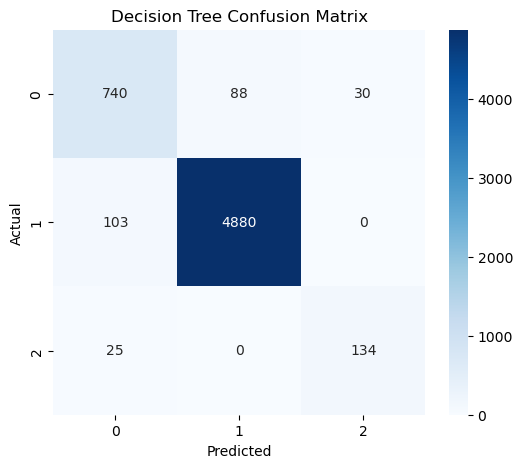

In [6]:
# ==========================================
# Confusion Matrix
# ==========================================

cm = confusion_matrix(
    y_test,
    dt_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [7]:
# ==========================================
# Classification Report
# ==========================================

print(

    classification_report(
        y_test,
        dt_pred
    )

)

              precision    recall  f1-score   support

           0       0.85      0.86      0.86       858
           1       0.98      0.98      0.98      4983
           2       0.82      0.84      0.83       159

    accuracy                           0.96      6000
   macro avg       0.88      0.89      0.89      6000
weighted avg       0.96      0.96      0.96      6000



In [8]:
# ==========================================
# Random Forest
# ==========================================

rf_model = RandomForestClassifier(

    n_estimators=200,

    random_state=42

)

rf_model.fit(

    X_train,

    y_train

)

rf_pred = rf_model.predict(

    X_test

)

print("Random Forest Trained Successfully")

Random Forest Trained Successfully


In [9]:
# ==========================================
# Random Forest Evaluation
# ==========================================

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    average="weighted"
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    average="weighted"
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    average="weighted"
)

print("Accuracy :", rf_accuracy)

print("Precision :", rf_precision)

print("Recall :", rf_recall)

print("F1 Score :", rf_f1)

Accuracy : 0.9631666666666666
Precision : 0.9633101517769463
Recall : 0.9631666666666666
F1 Score : 0.9628808515333908


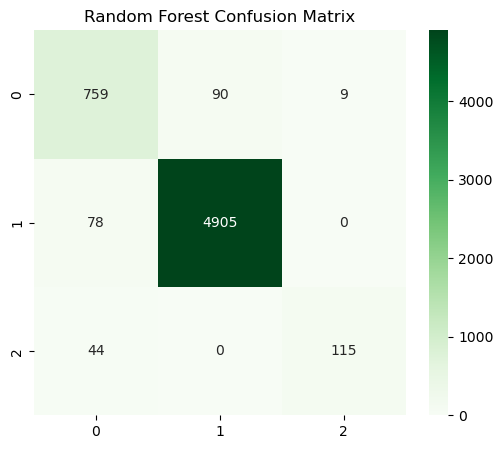

In [10]:
cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")

plt.show()

In [11]:
print(

    classification_report(

        y_test,

        rf_pred

    )

)

              precision    recall  f1-score   support

           0       0.86      0.88      0.87       858
           1       0.98      0.98      0.98      4983
           2       0.93      0.72      0.81       159

    accuracy                           0.96      6000
   macro avg       0.92      0.86      0.89      6000
weighted avg       0.96      0.96      0.96      6000



In [12]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(

    random_state=42,

    eval_metric="mlogloss"

)

xgb_model.fit(
    X_train,
    y_train
)

xgb_pred = xgb_model.predict(
    X_test
)

In [15]:
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred,
    average="weighted"
)

xgb_recall = recall_score(
    y_test,
    xgb_pred,
    average="weighted"
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred,
    average="weighted"
)

print("Accuracy :", xgb_accuracy)
print("Precision :", xgb_precision)
print("Recall :", xgb_recall)
print("F1 :", xgb_f1)

Accuracy : 0.9738333333333333
Precision : 0.9739059995112654
Recall : 0.9738333333333333
F1 : 0.9738275593795795


In [19]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    random_state=42
)

lgb_model.fit(
    X_train,
    y_train
)

lgb_pred = lgb_model.predict(
    X_test
)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007162 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 864
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 113
[LightGBM] [Info] Start training from score -1.944911
[LightGBM] [Info] Start training from score -0.185627
[LightGBM] [Info] Start training from score -3.633760


In [21]:
lgb_accuracy = accuracy_score(
    y_test,
    lgb_pred
)

lgb_precision = precision_score(
    y_test,
    lgb_pred,
    average="weighted"
)

lgb_recall = recall_score(
    y_test,
    lgb_pred,
    average="weighted"
)

lgb_f1 = f1_score(
    y_test,
    lgb_pred,
    average="weighted"
)

print("Accuracy :", lgb_accuracy)
print("Precision :", lgb_precision)
print("Recall :", lgb_recall)
print("F1 :", lgb_f1)

Accuracy : 0.9746666666666667
Precision : 0.9747597598920332
Recall : 0.9746666666666667
F1 : 0.9746692316179312


In [22]:
comparison = pd.DataFrame({

    "Model":[

        "Decision Tree",

        "Random Forest",

        "XGBoost",

        "LightGBM"

    ],

    "Accuracy":[

        dt_accuracy,

        rf_accuracy,

        xgb_accuracy,

        lgb_accuracy

    ],

    "Precision":[

        dt_precision,

        rf_precision,

        xgb_precision,

        lgb_precision

    ],

    "Recall":[

        dt_recall,

        rf_recall,

        xgb_recall,

        lgb_recall

    ],

    "F1 Score":[

        dt_f1,

        rf_f1,

        xgb_f1,

        lgb_f1

    ]

})

comparison.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
3,LightGBM,0.974667,0.974760,0.974667,0.974669
2,XGBoost,0.973833,0.973906,0.973833,0.973828
1,Random Forest,0.963167,0.963310,0.963167,0.962881
0,Decision Tree,0.959000,0.959354,0.959000,0.959166


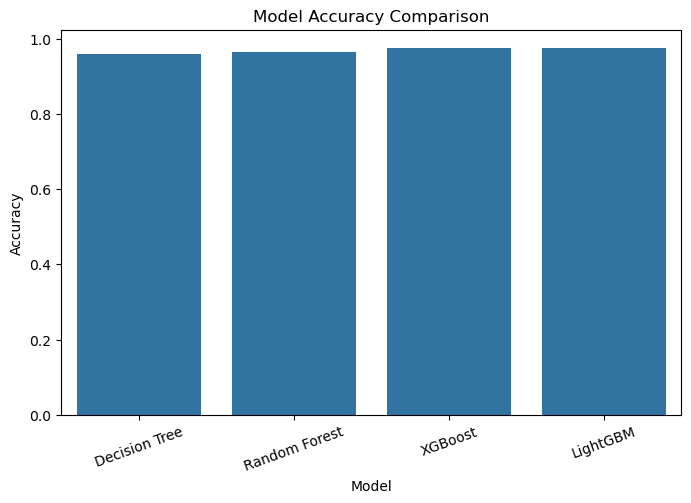

In [23]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")

plt.xticks(rotation=20)

plt.show()

In [26]:
import joblib

joblib.dump(
    lgb_model,
    "../models/best_model.pkl"
)

print("LightGBM model saved successfully!")

LightGBM model saved successfully!


In [25]:
comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        xgb_accuracy,
        lgb_accuracy
    ],
    "Precision": [
        dt_precision,
        rf_precision,
        xgb_precision,
        lgb_precision
    ],
    "Recall": [
        dt_recall,
        rf_recall,
        xgb_recall,
        lgb_recall
    ],
    "F1 Score": [
        dt_f1,
        rf_f1,
        xgb_f1,
        lgb_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.959000,0.959354,0.959000,0.959166
1,Random Forest,0.963167,0.963310,0.963167,0.962881
2,XGBoost,0.973833,0.973906,0.973833,0.973828
3,LightGBM,0.974667,0.974760,0.974667,0.974669
